# Chapter 2: Model Training and Fine-tuning
A) We'll choose a suitable model architecture and discuss the advantages and potential challenges associated with the selected model.

B) We'll perform hyperparameter tuning to optimize the model's performance. 

C) We'll address overfitting and underfitting during the training process.

D) We'll evaluate the trained model and discuss any limitations or potential areas for improvement.


In [24]:
%load_ext autoreload
%autoreload 2

### Required package imports

In [ ]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import DataLoader
from torchinfo import summary

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
import gc
import os
from datetime import datetime

import optuna
import mlflow
import mlflow.pytorch
from mlflow.models.signature import infer_signature

from resnet_hearthealth_monitor.config import BEST_MODEL_DIR, DEVICE
from resnet_hearthealth_monitor.modeling.resnet import ResNet125, ResNet
from resnet_hearthealth_monitor.data_processing.pytorch_datasets import augmentable_dataset
from resnet_hearthealth_monitor.data_processing.augmentations import Gaussian_Noise, Baseline_Wander, Stretch, Amplify
from resnet_hearthealth_monitor.modeling.train import run_study, train_model, optuna_objective, find_best_study
from resnet_hearthealth_monitor.plots import gen_training_loss_plots
from resnet_hearthealth_monitor.modeling.predict import testset_prediction


In [26]:
device = DEVICE
if device == 'cpu':
    print("WARNING: CUDA not available. Using CPU for training, which may be very slow.")

In [27]:
np.random.seed(42)
torch.manual_seed(42)

# A) Model selection


### We will use a modified version of the ResNet from Kachuee, Fazeli, & Sarrafzadeh's ECG heartbeat classification: A deep transferable representation. 

![ResNet Kachuee et al](../references/ResNet_Kachuee_et_al.png)

- Code for my implementation can be found at ../resnet_hearthealth_monitor/resnet.py
- The official publication can be found in ../references/

### Model modifications:

Given we cropped the timeseries after timepoint 125 during preprocessing, we needed to modify the network's orginal archtecture because it was built for timeseries of size 187. I decided to reduce maxpooling parameters to accomodate for this shorter signal. In the manuscript they report using a kernel size = 5 and a stride = 2, for our implementation we've used a kernel size = 3 and stride = 2. Our network has thus removed a large amount of processing of zero signal (timesteps 126-187) and instead used that network space to less aggressively downsample the good quality signal (timesteps 0-125). Hopefully this results in increased performance.

Considerations with respect to the Resnet chosen more generally:

Advantages: 
- strong performance demonstrated on this task
- simple, 
- well documented and long research history (high reliablity/certainty with respect to value-for-time-invested into constructing and training the model)

Disadvantages: 
- somewhat costly/slow to train
- probably will not perform terribly well when data distributions shift like during the holdout testing we will do for task 3, given supervised methods like resnets and cnns tend to rely more heavily on low-level features that the cnns capture rather than higher level/more abstract or transferable features like those that can be captured a bit better by self-supervised methods. 

# B) Hyperparameter tuning

We are performing hyperparameter tuning using an Optuna-based search through a hyperparameter space consisting of three dimensions: learning rate, batch size, and weight decay for the AdamW optimizer. 

Our methodology begins with the initiating of an Optuna study with variables including:
- a PyTorch model to use
- the hyperparameter space to sample
- the number of different hyperparameter combinations to try (n_trials)
- the number of epochs to allow the model to train for per trial
- the number of folds to use in the stratified k-fold splitting for each epoch 
- and any data augmentations we wish to apply 

A set of hyperparameters is sampled and sent to our function train_model() where the data is split using stratified cross-validation and the model is trained for n_epochs, logging train- and valid-set loss metrics per epoch.

During train_model():
- Each epoch where validation performance has improved, the model weights and biases are saved, overwritting the previous best model, resulting in 1 model per fold (see lines 115-116 in train.py)
- The learning rate changes if validation performance has not improved after 3 consecutive epochs
- Early stopping is initiated if validation performance has not improved after 6 consecutive epochs
- The best validation-set performance from each fold is then averaged to get a single performance metric (avg_best_val_loss) for this point in the hyperparameter space

After train_model():
- The avg_best_val_loss is returned to Optuna
- The hyperparameter space continues to be explored for n_trials

Prediction and inference:
- We then take whichever point in the hyperparameter space achieved the best avg_best_val_loss, load the fold-specific models that generated this result, and use these models to make predictions, taking the mode prediction from these models as the final prediction for a sample.

## Training our model in our model search program
With a 4090 this training takes about 50 minutes 

In [7]:
# Get train data
train_path = '../data/processed/mitbih_train_cropped.csv'
train_set = pd.read_csv(train_path, header=None)  

torch_model_class = ResNet125()
torch_dataset_class = augmentable_dataset
augmentations = [Gaussian_Noise(), Baseline_Wander(), Stretch(), Amplify()]

n_epochs = 10  
n_splits = 3
n_trials = 5

hyperparameter_space = {
    'lr': {
        'type': 'float',
        'low': 1e-5,
        'high': 1e-2,
        'log': True
    },
    'batch_size': {
        'type': 'categorical',
        'choices': [32, 64, 128, 256, 512]
    },
    'weight_decay': {
        'type': 'float',
        'low': 1e-5,
        'high': 1e-1,
        'log': True
    },
    # Add additional hyperparameters as needed.
}

# Generate a timestamped study name
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{timestamp}_ResNet125_firstpass_{n_trials}trials_{n_epochs}epochs_{n_splits}folds"

run_study(study_name, n_trials, train_set, torch_model_class, torch_dataset_class, augmentations, hyperparameter_space, n_epochs, n_splits, device)

2025/07/29 14:27:06 INFO mlflow.tracking.fluent: Experiment with name '20250729_142706_ResNet125_firstpass_5trials_10epochs_3folds' does not exist. Creating a new experiment.
[I 2025-07-29 14:27:06,572] A new study created in memory with name: 20250729_142706_ResNet125_firstpass_5trials_10epochs_3folds


2025-07-29 14:27:06.573 | SUCCESS  | lightweight_resnet_heart_monitor.modeling.train:run_study:222 - Optuna study and MLFlow records initiated in /home/anthony/home/github/lightweight_resnet_heart_monitor/models
{'lr': 0.002940743253283474, 'batch_size': 128, 'weight_decay': 0.0881646841286417}
Fold 0, Epoch 0: Train loss 7.46e-01, Val loss 5.89e-01, LR 2.94074e-03
Fold 0, Epoch 1: Train loss 4.55e-01, Val loss 5.59e-01, LR 2.94074e-03
Fold 0, Epoch 2: Train loss 3.96e-01, Val loss 4.51e-01, LR 2.94074e-03
Fold 0, Epoch 3: Train loss 3.59e-01, Val loss 3.40e-01, LR 2.94074e-03
Fold 0, Epoch 4: Train loss 3.48e-01, Val loss 4.44e-01, LR 2.94074e-03
Fold 0, Epoch 5: Train loss 3.29e-01, Val loss 1.96e-01, LR 2.94074e-03
Fold 0, Epoch 6: Train loss 3.28e-01, Val loss 3.87e-01, LR 2.94074e-03
Fold 0, Epoch 7: Train loss 3.05e-01, Val loss 4.42e-01, LR 2.94074e-03
Fold 0, Epoch 8: Train loss 3.16e-01, Val loss 5.06e-01, LR 2.94074e-03
Fold 0, Epoch 9: Train loss 2.97e-01, Val loss 4.25e-01,

[I 2025-07-29 14:38:05,335] Trial 0 finished with value: 0.18467380003248782 and parameters: {'lr': 0.002940743253283474, 'batch_size': 128, 'weight_decay': 0.0881646841286417}. Best is trial 0 with value: 0.18467380003248782.


{'lr': 0.006531954959554768, 'batch_size': 128, 'weight_decay': 0.0014420250054499124}
Fold 0, Epoch 0: Train loss 4.32e-01, Val loss 4.38e-01, LR 6.53195e-03
Fold 0, Epoch 1: Train loss 4.17e-01, Val loss 3.60e-01, LR 6.53195e-03
Fold 0, Epoch 2: Train loss 5.30e-01, Val loss 8.02e-01, LR 6.53195e-03
Fold 0, Epoch 3: Train loss 5.14e-01, Val loss 5.77e-01, LR 6.53195e-03
Fold 0, Epoch 4: Train loss 4.26e-01, Val loss 6.17e-01, LR 6.53195e-03
Fold 0, Epoch 5: Train loss 5.26e-01, Val loss 6.88e-01, LR 6.53195e-04
Fold 0, Epoch 6: Train loss 3.65e-01, Val loss 4.10e-01, LR 6.53195e-04
Fold 0, Epoch 7: Train loss 3.14e-01, Val loss 3.51e-01, LR 6.53195e-04
Fold 0, Epoch 8: Train loss 2.92e-01, Val loss 2.44e-01, LR 6.53195e-04
Fold 0, Epoch 9: Train loss 2.83e-01, Val loss 3.15e-01, LR 6.53195e-04
Fold 1, Epoch 0: Train loss 5.27e-01, Val loss 7.27e-01, LR 6.53195e-03
Fold 1, Epoch 1: Train loss 6.03e-01, Val loss 6.24e-01, LR 6.53195e-03
Fold 1, Epoch 2: Train loss 4.78e-01, Val loss 4.

[I 2025-07-29 14:48:53,461] Trial 1 finished with value: 0.32640570358324833 and parameters: {'lr': 0.006531954959554768, 'batch_size': 128, 'weight_decay': 0.0014420250054499124}. Best is trial 0 with value: 0.18467380003248782.


{'lr': 0.0005957516982678065, 'batch_size': 128, 'weight_decay': 0.05925152410887136}
Fold 0, Epoch 0: Train loss 3.14e-01, Val loss 3.53e-01, LR 5.95752e-04
Fold 0, Epoch 1: Train loss 2.81e-01, Val loss 2.98e-01, LR 5.95752e-04
Fold 0, Epoch 2: Train loss 2.75e-01, Val loss 3.20e-01, LR 5.95752e-04
Fold 0, Epoch 3: Train loss 2.67e-01, Val loss 3.43e-01, LR 5.95752e-04
Fold 0, Epoch 4: Train loss 2.56e-01, Val loss 2.77e-01, LR 5.95752e-04
Fold 0, Epoch 5: Train loss 2.60e-01, Val loss 3.13e-01, LR 5.95752e-04
Fold 0, Epoch 6: Train loss 2.49e-01, Val loss 2.85e-01, LR 5.95752e-04
Fold 0, Epoch 7: Train loss 2.48e-01, Val loss 2.90e-01, LR 5.95752e-04
Fold 0, Epoch 8: Train loss 2.39e-01, Val loss 3.49e-01, LR 5.95752e-05
Fold 0, Epoch 9: Train loss 2.39e-01, Val loss 2.79e-01, LR 5.95752e-05
Fold 1, Epoch 0: Train loss 2.39e-01, Val loss 2.78e-01, LR 5.95752e-04
Fold 1, Epoch 1: Train loss 2.42e-01, Val loss 2.87e-01, LR 5.95752e-04
Fold 1, Epoch 2: Train loss 2.40e-01, Val loss 2.7

... (2 outputs left out)

[I 2025-07-29 15:09:41,469] Trial 3 finished with value: 0.19173683988829626 and parameters: {'lr': 0.00016031096913510974, 'batch_size': 256, 'weight_decay': 0.0017089901772878895}. Best is trial 0 with value: 0.18467380003248782.


{'lr': 1.3398522893783712e-05, 'batch_size': 256, 'weight_decay': 0.0001456816129179694}
Fold 0, Epoch 0: Train loss 1.74e-01, Val loss 1.85e-01, LR 1.33985e-05
Fold 0, Epoch 1: Train loss 1.67e-01, Val loss 1.87e-01, LR 1.33985e-05
Fold 0, Epoch 2: Train loss 1.69e-01, Val loss 1.92e-01, LR 1.33985e-05
Fold 0, Epoch 3: Train loss 1.63e-01, Val loss 1.90e-01, LR 1.33985e-05
Fold 0, Epoch 4: Train loss 1.64e-01, Val loss 1.89e-01, LR 1.33985e-06
Fold 0, Epoch 5: Train loss 1.74e-01, Val loss 1.89e-01, LR 1.33985e-06
Fold 0, Epoch 6: Train loss 1.68e-01, Val loss 1.90e-01, LR 1.33985e-06
Fold 0: Early stopping triggered at epoch 6
Fold 1, Epoch 0: Train loss 1.70e-01, Val loss 1.91e-01, LR 1.33985e-05
Fold 1, Epoch 1: Train loss 1.59e-01, Val loss 1.93e-01, LR 1.33985e-05
Fold 1, Epoch 2: Train loss 1.72e-01, Val loss 1.98e-01, LR 1.33985e-05
Fold 1, Epoch 3: Train loss 1.67e-01, Val loss 1.98e-01, LR 1.33985e-05
Fold 1, Epoch 4: Train loss 1.65e-01, Val loss 2.00e-01, LR 1.33985e-06
Fol

[I 2025-07-29 15:17:41,867] Trial 4 finished with value: 0.18785022416997743 and parameters: {'lr': 1.3398522893783712e-05, 'batch_size': 256, 'weight_decay': 0.0001456816129179694}. Best is trial 0 with value: 0.18467380003248782.


2025-07-29 15:17:41.868 | SUCCESS  | lightweight_resnet_heart_monitor.modeling.train:run_study:245 - Best hyperparameters: {'lr': 0.002940743253283474, 'batch_size': 128, 'weight_decay': 0.0881646841286417}
2025-07-29 15:17:41.868 | SUCCESS  | lightweight_resnet_heart_monitor.modeling.train:run_study:246 - Best validation loss: 0.18467380003248782
2025-07-29 15:17:41.870 | SUCCESS  | lightweight_resnet_heart_monitor.modeling.train:run_study:254 - Study saved to /home/anthony/home/github/lightweight_resnet_heart_monitor/models under filename 20250729_142706_ResNet125_firstpass_5trials_10epochs_3folds


# C) Addressing overfitting and underfitting

To ensure our model generalizes well and avoids both overfitting and underfitting, we implemented several techniques:

**Stratified Cross-Validation:**
Our stratified cross-validation provides a robust estimate of performance by ensuring the model is trained and evaluated on different splits of the data and no class is over- or under-sampled

**Hyperparameter Tuning:**
We used Optuna to dynamically optimize hyperparameters such as learning rate, batch size, and weight decay. This automated search helps us balance the model's complexity and regularization, thereby preventing both underfitting (by ensuring the model is expressive enough) and overfitting (by tuning regularization parameters).

**Learning rate scheduling:**
Our learning rate scheduler ReduceLROnPlateau helps protect against underfitting and overfitting as well. Constraining the size of updates to shrink if validation performance is not improving encourages better generalization/a reduction in overfitting by slowing the model's learning if it begins learning from training noise not found in the validation set. Additionally, protect against underfitting can occur in situations where updates are too large/get stuck bouncing around a minimum without following it. 

**Early Stopping:**
Our early stopping halts training once performance stops improving after 6 epochs (value currently hardcoded), which helps prevent overfitting to the train-set.

**Data Augmentation:**
As discussed in chapter_1_data_processing.ipynb, we applied domain-specific augmentations—such as baseline wander, Gaussian noise, amplification, and time stretching/shrinking—to simulate realistic variations in ECG signals. This effectively increases the diversity of our training data, which helps prevent overfitting by exposing the model to a wider range of signal variations.

**Class Imbalance Management:**
Given the heavily imbalanced nature of our dataset, we incorporated class weights in our loss function to penalize errors on minority classes more. This strategy encourages the model to learn robust features for all classes and avoids overfitting to the majority class. The weights and application to our cross-entropy loss can be seen in train.py lines 66-67. In combination with our stratification of the cross-validation process we can be confident that the model will be exposed to minority classes and will learn from these exposures.


# D) Evaluating the trained model

### Find best model from completed Optuna studies

In [8]:
find_best_study()

2025-07-29 15:19:13.202 | INFO     | lightweight_resnet_heart_monitor.modeling.train:find_best_study:259 - Loading all model searches stored in /home/anthony/home/github/lightweight_resnet_heart_monitor/models.
2025-07-29 15:19:13.202 | INFO     | lightweight_resnet_heart_monitor.modeling.train:find_best_study:266 - Examining best performances from each search.
Study file '20250729_142706_ResNet125_firstpass_5trials_10epochs_3folds.pkl' has best_trial.value: 0.18467380003248782
Study file '20250302_140242_ResNet125_firstpass_5trials_10epochs_3folds.pkl' has best_trial.value: 0.11959997662995088
2025-07-29 15:19:13.205 | SUCCESS  | lightweight_resnet_heart_monitor.modeling.train:find_best_study:286 - Best study file is: '/home/anthony/home/github/lightweight_resnet_heart_monitor/models/20250302_140242_ResNet125_firstpass_5trials_10epochs_3folds.pkl' with score 0.11959997662995088
Removed existing file: 20250302_140242_ResNet125_firstpass_5trials_10epochs_3folds.pkl
2025-07-29 15:19:13.2

### Examine loss plots of train and validation loss during cross-validated training

Saved average learning curve plot to /home/anthony/home/github/lightweight_resnet_heart_monitor/reports/figures/avg_learning_curve_over_folds.png


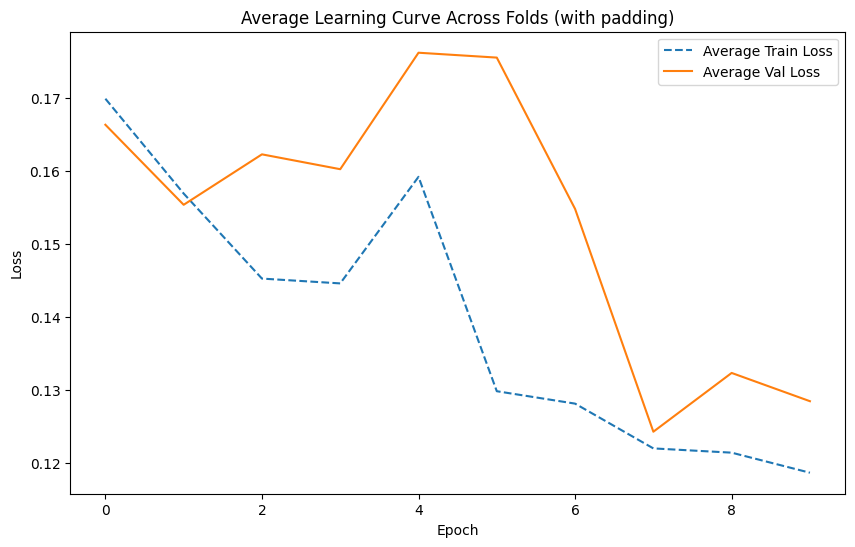

Saved fold learning curves plot to /home/anthony/home/github/lightweight_resnet_heart_monitor/reports/figures/learning_curves_per_fold.png


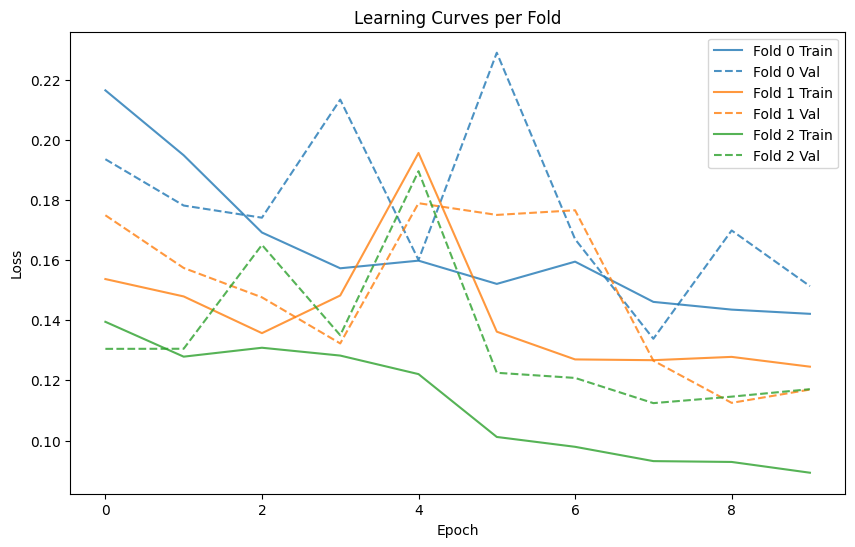

2025-07-29 15:19:55.016 | SUCCESS  | lightweight_resnet_heart_monitor.plots:gen_training_loss_plots:82 - Loss plots generated and saved to /home/anthony/home/github/lightweight_resnet_heart_monitor/reports/figures


In [10]:
gen_training_loss_plots()

# Evaluate model performance on held-out test set

In [13]:
test_path = '../data/processed/mitbih_test_cropped.csv'
test_set = pd.read_csv(test_path, header=None)  

testset_predictions_and_labels_df = testset_prediction(test_set, torch_model_class, torch_dataset_class, device, save_and_display_results=True)

2025-07-29 15:28:34.909 | SUCCESS  | lightweight_resnet_heart_monitor.modeling.predict:testset_prediction:65 - Test-set predictions saved to /home/anthony/home/github/lightweight_resnet_heart_monitor/models/best_model/testset_predictions_and_labels.csv.
True label distribution:
Label
0.0    18118
4.0     1608
2.0     1448
1.0      556
3.0      162
Name: count, dtype: int64

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.96      0.98     18118
         1.0       0.53      0.87      0.66       556
         2.0       0.93      0.95      0.94      1448
         3.0       0.42      0.93      0.58       162
         4.0       0.97      0.99      0.98      1608

    accuracy                           0.96     21892
   macro avg       0.77      0.94      0.83     21892
weighted avg       0.97      0.96      0.96     21892

final_predictions_and_labels['Label']:
0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
       

## Model Strength

The model has a nice property of having quite high recall scores for the minority classes and quite high precision for the majority, which is exactly what we would like in a situation like this where the minority classes represent potential health problems that may require further testing/investigation while the majority is just average/healthy timeseries. Better to do an unneeded follow-up on a healthy ECG than miss doing a needed follow-up on a problematic ECG.